# Feature Importance Visualization

This section visualizes the most important features from each model based on the feature importance analysis.

In [1]:
# Load feature importance data from all models
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np

# Load feature importance CSVs
cox_features = pd.read_csv('cox_feature_importance.csv')
gbm_features = pd.read_csv('gbm_feature_importance.csv')
rsf_features = pd.read_csv('rsf_feature_importance.csv')
ssvm_features = pd.read_csv('ssvm_feature_importance.csv')

print("Feature importance data loaded successfully!")
print(f"\nCox features: {len(cox_features)} features")
print(f"GBM features: {len(gbm_features)} features")
print(f"RSF features: {len(rsf_features)} features")
print(f"SSVM features: {len(ssvm_features)} features")

print("\nTop 5 Cox features:")
print(cox_features.head())

Feature importance data loaded successfully!

Cox features: 48 features
GBM features: 48 features
RSF features: 48 features
SSVM features: 48 features

Top 5 Cox features:
                                             Feature  Coefficient_Mean  \
0                Oestrogen receptor status at CB_1.0         -0.606520   
1  Her2 overexpression (with immunohystochemistry...         -0.347275   
2                                 Istotype at CB_1.0         -0.315014   
3                Oestrogen receptor status at CB_0.0          0.277699   
4  Her2 overexpression (with immunohystochemistry...          0.237364   

   Coefficient_Std  Abs_Coefficient  Hazard_Ratio  
0         0.138366         0.606520      0.545245  
1         0.115676         0.347275      0.706611  
2         0.095273         0.315014      0.729778  
3         0.184927         0.277699      1.320088  
4         0.185698         0.237364      1.267902  


In [2]:
# Analyze how many features each model is actually using (non-zero importance)
import pandas as pd
import numpy as np

print("="*80)
print("FEATURE USAGE ANALYSIS")
print("="*80)

# Cox Model - Features with non-zero coefficients
cox_nonzero = cox_features[cox_features['Abs_Coefficient'] > 0]
print(f"\nCox (CoxNet):")
print(f"  Total features available: {len(cox_features)}")
print(f"  Features with non-zero coefficients: {len(cox_nonzero)}")
print(f"  Percentage used: {len(cox_nonzero)/len(cox_features)*100:.2f}%")

# GBM Model - Features with non-zero importance
gbm_nonzero = gbm_features[gbm_features['Importance_Mean'] > 0]
print(f"\nGBM:")
print(f"  Total features available: {len(gbm_features)}")
print(f"  Features with non-zero importance: {len(gbm_nonzero)}")
print(f"  Percentage used: {len(gbm_nonzero)/len(gbm_features)*100:.2f}%")

# RSF Model - Features with non-zero importance
rsf_nonzero = rsf_features[rsf_features['Importance'] > 0]
print(f"\nRSF:")
print(f"  Total features available: {len(rsf_features)}")
print(f"  Features with non-zero importance: {len(rsf_nonzero)}")
print(f"  Percentage used: {len(rsf_nonzero)/len(rsf_features)*100:.2f}%")

# SSVM Model - Features with non-zero importance
ssvm_nonzero = ssvm_features[ssvm_features['Importance'] > 0]
print(f"\nSSVM:")
print(f"  Total features available: {len(ssvm_features)}")
print(f"  Features with non-zero importance: {len(ssvm_nonzero)}")
print(f"  Percentage used: {len(ssvm_nonzero)/len(ssvm_features)*100:.2f}%")

print("\n" + "="*80)
print("SUMMARY")
print("="*80)

summary_data = {
    'Model': ['Cox', 'GBM', 'RSF', 'SSVM'],
    'Total Features': [len(cox_features), len(gbm_features), len(rsf_features), len(ssvm_features)],
    'Features Used': [len(cox_nonzero), len(gbm_nonzero), len(rsf_nonzero), len(ssvm_nonzero)],
    'Percentage Used': [
        f"{len(cox_nonzero)/len(cox_features)*100:.2f}%",
        f"{len(gbm_nonzero)/len(gbm_features)*100:.2f}%",
        f"{len(rsf_nonzero)/len(rsf_features)*100:.2f}%",
        f"{len(ssvm_nonzero)/len(ssvm_features)*100:.2f}%",
    ]
}

summary_df = pd.DataFrame(summary_data)

# Initialize and update unique_features_used for all models
unique_features_used = set()
unique_features_used.update(cox_nonzero['Feature'].tolist())
unique_features_used.update(gbm_nonzero['Feature'].tolist())
unique_features_used.update(rsf_nonzero['Feature'].tolist())
unique_features_used.update(ssvm_nonzero['Feature'].tolist())

# Total unique features available (assuming all models have same feature set)
unique_features_available = set(cox_features['Feature'].tolist())

print(f"\nUNIQUE FEATURES USED ACROSS ALL MODELS: {len(unique_features_used)}")
print(f"TOTAL UNIQUE FEATURES AVAILABLE: {len(unique_features_available)}")
print(f"OVERALL PERCENTAGE USED: {len(unique_features_used)/len(unique_features_available)*100:.2f}%")
print("="*80)

# Show overlap analysis
print("\n" + "="*80)
print("FEATURE OVERLAP ANALYSIS")
print("="*80)
cox_set = set(cox_nonzero['Feature'].tolist())
gbm_set = set(gbm_nonzero['Feature'].tolist())
rsf_set = set(rsf_nonzero['Feature'].tolist())
ssvm_set = set(ssvm_nonzero['Feature'].tolist())

print(f"\nFeatures used by all 4 models: {len(cox_set & gbm_set & rsf_set & ssvm_set)}")
print(f"Features used by at least 3 models: {len([f for f in unique_features_used if sum([f in s for s in [cox_set, gbm_set, rsf_set, ssvm_set]]) >= 3])}")
print(f"Features used by at least 2 models: {len([f for f in unique_features_used if sum([f in s for s in [cox_set, gbm_set, rsf_set, ssvm_set]]) >= 2])}")
print(f"Features unique to one model: {len([f for f in unique_features_used if sum([f in s for s in [cox_set, gbm_set, rsf_set, ssvm_set]]) == 1])}")
print("="*80)

# Optional: Show top 10 most important features for each model
print("\n" + "="*80)
print("TOP 10 FEATURES PER MODEL")
print("="*80)

print("\nCox (Top 10):")
print(cox_features.nlargest(10, 'Abs_Coefficient')[['Feature', 'Abs_Coefficient']].to_string(index=False))

print("\nGBM (Top 10):")
print(gbm_features.nlargest(10, 'Importance_Mean')[['Feature', 'Importance_Mean']].to_string(index=False))

print("\nRSF (Top 10):")
print(rsf_features.nlargest(10, 'Importance')[['Feature', 'Importance']].to_string(index=False))

print("\nSSVM (Top 10):")
print(ssvm_features.nlargest(10, 'Importance')[['Feature', 'Importance']].to_string(index=False))

FEATURE USAGE ANALYSIS

Cox (CoxNet):
  Total features available: 48
  Features with non-zero coefficients: 38
  Percentage used: 79.17%

GBM:
  Total features available: 48
  Features with non-zero importance: 38
  Percentage used: 79.17%

RSF:
  Total features available: 48
  Features with non-zero importance: 17
  Percentage used: 35.42%

SSVM:
  Total features available: 48
  Features with non-zero importance: 24
  Percentage used: 50.00%

SUMMARY

UNIQUE FEATURES USED ACROSS ALL MODELS: 45
TOTAL UNIQUE FEATURES AVAILABLE: 48
OVERALL PERCENTAGE USED: 93.75%

FEATURE OVERLAP ANALYSIS

Features used by all 4 models: 11
Features used by at least 3 models: 22
Features used by at least 2 models: 39
Features unique to one model: 6

TOP 10 FEATURES PER MODEL

Cox (Top 10):
                                                  Feature  Abs_Coefficient
                      Oestrogen receptor status at CB_1.0         0.606520
Her2 overexpression (with immunohystochemistry) at CB_2.0         0.3

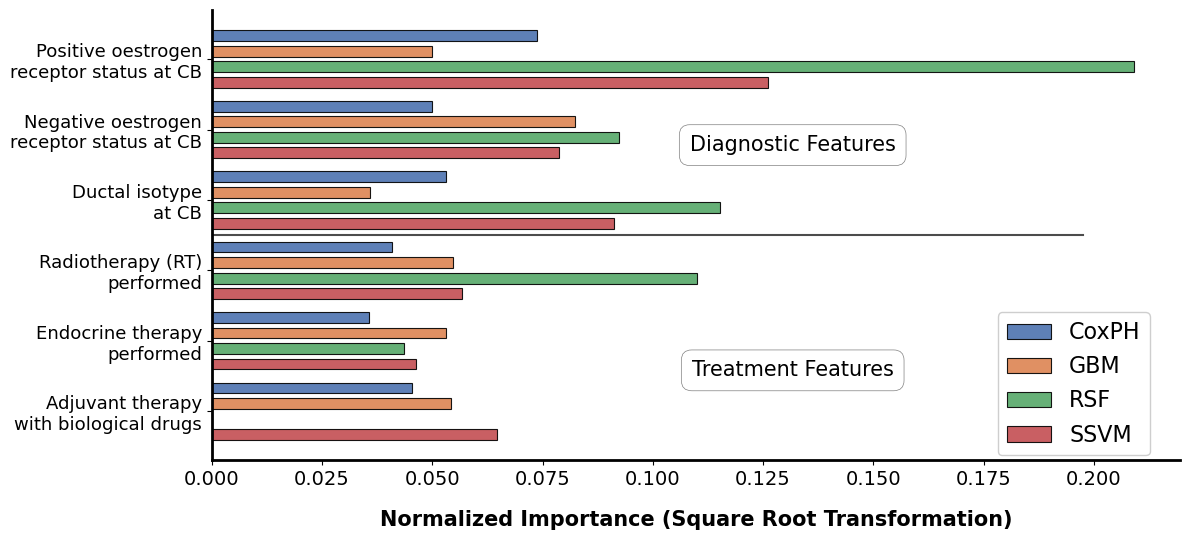

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# --- 1. COLLECT ALL FEATURES (Not just top N) ---
all_features_dict = {}

for model_name, features_df, imp_col in zip(
    ['CoxPH', 'GBM', 'RSF', 'SSVM'], 
    [cox_features, gbm_features, rsf_features, ssvm_features],
    ['Abs_Coefficient', 'Importance_Mean', 'Importance', 'Importance']
):
    # Iterate through EVERY feature in the dataframe, not just the top N
    for _, row in features_df.iterrows():
        feature_name = row['Feature']
        importance = row[imp_col]
        
        if feature_name not in all_features_dict:
            all_features_dict[feature_name] = {}
        all_features_dict[feature_name][model_name] = importance

# Convert to DataFrame (Rows = Features, Cols = Raw Importance)
feature_matrix = pd.DataFrame(all_features_dict).T.fillna(0)

# --- 2. NORMALIZE ALL FEATURES (Square-Root + Sum) ---
for col in feature_matrix.columns:
    clean_series = feature_matrix[col].clip(lower=0)
    # 1. Apply Square Root to dampen the huge GBM spikes
    compressed_values = np.sqrt(clean_series)
    
    # 2. Sum-Normalize so each model's total weight = 1.0 (100%)
    total_importance = compressed_values.sum()
    if total_importance > 0:
        feature_matrix[f'{col}_norm'] = compressed_values / total_importance
    else:
        feature_matrix[f'{col}_norm'] = 0

# --- 3. CALCULATE AVERAGE & SELECT TOP N ---
norm_cols = [col for col in feature_matrix.columns if col.endswith('_norm')]
feature_matrix['Avg_Importance'] = feature_matrix[norm_cols].mean(axis=1)

# NOW we select the top features for the poster
number_feat = 6  # Show top 12 features on the poster
top_combined = feature_matrix.nlargest(number_feat, 'Avg_Importance')

# --- 4. ASSIGN CATEGORIES ---
feature_categories = {
    'Endocrine therapy performed': 'Treatment',
    'Chemotherapy performed': 'Treatment',
    'Radiation therapy performed': 'Treatment',
    'Grade at CB_3.0': 'Diagnostic',
    'Oestrogen receptor status': 'Diagnostic',
    'Ki67 positive cells (%) at CB': 'Diagnostic',
    'Oestrogen receptor status at CB_0.0': 'Diagnostic',
    'Radiotherapy (RT) performed': 'Treatment',
    'Oestrogen receptor status at CB_1.0': 'Diagnostic',
    'Adjuvant therapy with bio drugs': 'Treatment',
    'N (Regional nodes affected)': 'Diagnostic',
    'Total administered dose': 'Treatment',
    'Conventional RT fraction': 'Treatment',
    'Radiotherapy on chest wall': 'Treatment',
    'Age':'Diagnostic',
    'Istotype at CB_1.0': 'Diagnostic',
    'Progesterone receptor status at CB_1.0': 'Diagnostic'
}

# Add line breaks to long feature names
def wrap_feature_name(name):
    """Add line breaks to long feature names"""
    wrapping_rules = {
        'Endocrine therapy performed': 'Endocrine therapy\nperformed',
        'Chemotherapy performed': 'Chemotherapy\nperformed',
        'Radiation therapy performed': 'Radiation therapy\nperformed',
        'Ki67 positive cells (%) at CB': 'Ki67 positive cells\n(%) at CB',
        'Oestrogen receptor status at CB_0.0': 'Negative oestrogen\nreceptor status at CB',
        'Radiotherapy (RT) performed': 'Radiotherapy (RT)\nperformed',
        'Oestrogen receptor status at CB_1.0': 'Positive oestrogen\nreceptor status at CB',
        'Adjuvant therapy with bio drugs': 'Adjuvant therapy\nwith biological drugs',
        'N (Regional nodes affected)': 'N (Regional nodes\naffected)',
        'Conventional RT fraction': 'Conventional RT\nfraction',
        'Radiotherapy on chest wall': 'Radiotherapy on\nchest wall',
        'Istotype at CB_1.0': 'Ductal isotype\nat CB',
        'Progesterone receptor status at CB_1.0': 'Positive progesterone\nreceptor status at CB',
        'Total administered dose': 'Total administered\ndose'
    }
    return wrapping_rules.get(name, name)

all_features = top_combined.index.tolist()

# Intelligent fallback for missing categories
for feature in all_features:
    if feature not in feature_categories:
        print(f"WARNING: Feature '{feature}' not found in category dict. Assigning to 'Diagnostic'.")
        feature_categories[feature] = 'Diagnostic' # Safer default

top_combined['Category'] = top_combined.index.map(feature_categories)

# Sort: First by Category (Diagnostic bottom, Treatment top), then by Importance
top_combined_sorted = top_combined.sort_values(['Category', 'Avg_Importance'], ascending=[False, True])

# --- 5. PLOTTING ---
fig, ax = plt.subplots(figsize=(12, 5.5))

ax.yaxis.grid(False)
ax.xaxis.grid(False)

# Set white background inside axes only
ax.set_facecolor('white')

models = ['CoxPH', 'GBM', 'RSF', 'SSVM']

colors = ['#4C72B0', '#DD8452', '#55A868', '#C44E52'] # Blue, Orange, Green, Re
# Side-by-side bars configuration
n_models = len(models)
y_pos = np.arange(len(top_combined_sorted))
bar_height = 0.15  # Height of each bar (total ~0.72 for 4 bars)
bar_spacing = 0.07  # Small gap between bars

# Reverse the order so Cox is plotted last (on top)
for i, (model, color) in enumerate(zip(models[::-1], colors[::-1])):
    norm_col = f'{model}_norm'
    if norm_col in top_combined_sorted.columns:
        values = top_combined_sorted[norm_col].values
        # Calculate y position for each model (side by side)
        offset = (i - (n_models - 1) / 2) * (bar_height + bar_spacing)
        ax.barh(y_pos + offset, values, height=bar_height, label=model, color=color, 
                alpha=0.9, edgecolor='black', linewidth=0.8)

# Labels and Styling
feature_names = [wrap_feature_name(name) for name in top_combined_sorted.index.tolist()]
categories = top_combined_sorted['Category'].tolist()

ax.set_yticks(y_pos)
ax.set_yticklabels(feature_names, fontsize=13) # Increased font
ax.set_xlabel('Normalized Importance (Square Root Transformation)', fontsize=15, fontweight='bold', labelpad=15)

# Add Separator Lines
current_category = None
for i, (pos, category) in enumerate(zip(y_pos, categories)):
    if category != current_category:
        if current_category is not None:
            ax.axhline(y=pos - 0.5, color='black', linestyle='-', linewidth=1.5, alpha=0.7,xmax=0.90)
        current_category = category

# Category Labels - centered between groups
unique_cats = list(set(categories))
for cat in unique_cats:
    indices = [i for i, c in enumerate(categories) if c == cat]
    if indices:
        # Center label between min and max index of the group
        position_data = (min(indices) + max(indices)) / 2
        position_axes = ((position_data + 0.5) / len(top_combined_sorted)) - 0.05
        if cat == 'Treatment':
            cat_label = 'Treatment Features'
        else:
            cat_label = 'Diagnostic Features'
        ax.text(0.6, position_axes, cat_label, transform=ax.transAxes,
                fontsize=15, rotation=0, va='center', ha='center',
                bbox=dict(boxstyle='round,pad=0.5', facecolor='white', alpha=1.0, edgecolor='gray', linewidth=0.5))

# Fix legend order to match bar order (Cox at top)
handles, labels = ax.get_legend_handles_labels()
ax.legend(handles[::-1], labels[::-1], bbox_to_anchor=(0.98, 0.17), loc='center right', fontsize=16, framealpha=0.95)
ax.tick_params(axis='x', labelsize=14)

# Remove right and top borders
ax.spines['right'].set_visible(False)
ax.spines['top'].set_visible(False)
# Keep left and bottom borders thick for poster
ax.spines['left'].set_edgecolor('black')
ax.spines['left'].set_linewidth(2.0)
ax.spines['bottom'].set_edgecolor('black')
ax.spines['bottom'].set_linewidth(2.0)

plt.tight_layout()
plt.savefig('feature_importance_final.pdf', transparent=True, dpi=600, bbox_inches='tight')
plt.show()  

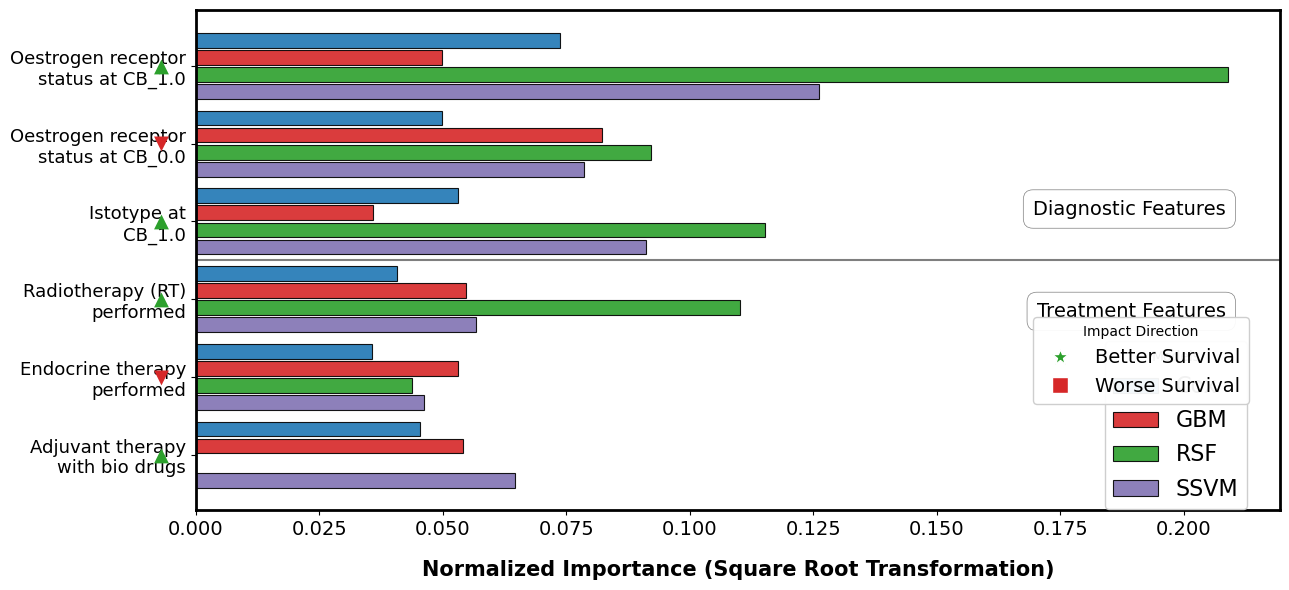


FEATURE IMPACT DIRECTION (Based on Cox Model Coefficients)
Adjuvant therapy with bio drugs                    : Better
Endocrine therapy performed                        : Worse
Radiotherapy (RT) performed                        : Better
Istotype at CB_1.0                                 : Better
Oestrogen receptor status at CB_0.0                : Worse
Oestrogen receptor status at CB_1.0                : Better


In [4]:
# Add directional impact information (positive/negative effect on survival)
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import FancyBboxPatch

# --- 1. COLLECT ALL FEATURES WITH DIRECTIONALITY ---
all_features_dict = {}
all_features_direction = {}  # Store direction information

for model_name, features_df, imp_col in zip(
    ['Cox', 'GBM', 'RSF', 'SSVM'], 
    [cox_features, gbm_features, rsf_features, ssvm_features],
    ['Abs_Coefficient', 'Importance_Mean', 'Importance', 'Importance']
):
    # Iterate through EVERY feature in the dataframe
    for _, row in features_df.iterrows():
        feature_name = row['Feature']
        importance = row[imp_col]
        
        if feature_name not in all_features_dict:
            all_features_dict[feature_name] = {}
            all_features_direction[feature_name] = {}
        
        all_features_dict[feature_name][model_name] = importance
        
        # For Cox model, use the actual coefficient to determine direction
        if model_name == 'Cox' and 'Coefficient_Mean' in features_df.columns:
            # Positive coefficient = increased hazard = worse survival (negative impact)
            # Negative coefficient = decreased hazard = better survival (positive impact)
            all_features_direction[feature_name][model_name] = 'Negative' if row['Coefficient_Mean'] > 0 else 'Positive'
        else:
            # For other models, we don't have inherent directionality from importance alone
            all_features_direction[feature_name][model_name] = 'Unknown'

# Convert to DataFrame
feature_matrix = pd.DataFrame(all_features_dict).T.fillna(0)
direction_matrix = pd.DataFrame(all_features_direction).T.fillna('Unknown')

# --- 2. NORMALIZE ALL FEATURES ---
for col in feature_matrix.columns:
    clean_series = feature_matrix[col].clip(lower=0)
    compressed_values = np.sqrt(clean_series)
    total_importance = compressed_values.sum()
    if total_importance > 0:
        feature_matrix[f'{col}_norm'] = compressed_values / total_importance
    else:
        feature_matrix[f'{col}_norm'] = 0

# --- 3. CALCULATE AVERAGE & SELECT TOP N ---
norm_cols = [col for col in feature_matrix.columns if col.endswith('_norm')]
feature_matrix['Avg_Importance'] = feature_matrix[norm_cols].mean(axis=1)

number_feat = 6
top_combined = feature_matrix.nlargest(number_feat, 'Avg_Importance')

# Add direction info for top features
direction_info = {}
for feature in top_combined.index:
    if feature in direction_matrix.index and 'Cox' in direction_matrix.columns:
        direction_info[feature] = direction_matrix.loc[feature, 'Cox']
    else:
        direction_info[feature] = 'Unknown'

# --- 4. ASSIGN CATEGORIES ---
feature_categories = {
    'Endocrine therapy performed': 'Treatment',
    'Chemotherapy performed': 'Treatment',
    'Radiation therapy performed': 'Treatment',
    'Grade at CB_3.0': 'Diagnostic',
    'Oestrogen receptor status': 'Diagnostic',
    'Ki67 positive cells (%) at CB': 'Diagnostic',
    'Oestrogen receptor status at CB_0.0': 'Diagnostic',
    'Radiotherapy (RT) performed': 'Treatment',
    'Oestrogen receptor status at CB_1.0': 'Diagnostic',
    'Adjuvant therapy with bio drugs': 'Treatment',
    'N (Regional nodes affected)': 'Diagnostic',
    'Total administered dose': 'Treatment',
    'Conventional RT fraction': 'Treatment',
    'Radiotherapy on chest wall': 'Treatment',
    'Age':'Diagnostic',
    'Istotype at CB_1.0': 'Diagnostic',
    'Progesterone receptor status at CB_1.0': 'Diagnostic'
}

def wrap_feature_name(name):
    wrapping_rules = {
        'Endocrine therapy performed': 'Endocrine therapy\nperformed',
        'Chemotherapy performed': 'Chemotherapy\nperformed',
        'Radiation therapy performed': 'Radiation therapy\nperformed',
        'Oestrogen receptor status': 'Oestrogen receptor\nstatus',
        'Ki67 positive cells (%) at CB': 'Ki67 positive cells\n(%) at CB',
        'Oestrogen receptor status at CB_0.0': 'Oestrogen receptor\nstatus at CB_0.0',
        'Radiotherapy (RT) performed': 'Radiotherapy (RT)\nperformed',
        'Oestrogen receptor status at CB_1.0': 'Oestrogen receptor\nstatus at CB_1.0',
        'Adjuvant therapy with bio drugs': 'Adjuvant therapy\nwith bio drugs',
        'N (Regional nodes affected)': 'N (Regional nodes\naffected)',
        'Conventional RT fraction': 'Conventional RT\nfraction',
        'Radiotherapy on chest wall': 'Radiotherapy on\nchest wall',
        'Istotype at CB_1.0': 'Istotype at\nCB_1.0',
        'Progesterone receptor status at CB_1.0': 'Progesterone receptor\nstatus at CB_1.0',
        'Total administered dose': 'Total administered\ndose'
    }
    return wrapping_rules.get(name, name)

all_features = top_combined.index.tolist()

for feature in all_features:
    if feature not in feature_categories:
        print(f"WARNING: Feature '{feature}' not found in category dict. Assigning to 'Diagnostic'.")
        feature_categories[feature] = 'Diagnostic'

top_combined['Category'] = top_combined.index.map(feature_categories)
top_combined['Direction'] = top_combined.index.map(direction_info)

# Sort
top_combined_sorted = top_combined.sort_values(['Category', 'Avg_Importance'], ascending=[False, True])

# --- 5. PLOTTING WITH DIRECTIONAL INDICATORS ---
fig, ax = plt.subplots(figsize=(13, 6))

ax.yaxis.grid(False)
ax.xaxis.grid(False)
ax.set_facecolor('white')

models = ['Cox', 'GBM', 'RSF', 'SSVM']
colors = ['#1F77B4', '#D62728', '#2CA02C', '#8172B3']

n_models = len(models)
y_pos = np.arange(len(top_combined_sorted))
bar_height = 0.19
bar_spacing = 0.03

# Reverse the order so Cox is plotted last (on top)
for i, (model, color) in enumerate(zip(models[::-1], colors[::-1])):
    norm_col = f'{model}_norm'
    if norm_col in top_combined_sorted.columns:
        values = top_combined_sorted[norm_col].values
        offset = (i - (n_models - 1) / 2) * (bar_height + bar_spacing)
        ax.barh(y_pos + offset, values, height=bar_height, label=model, color=color, 
                alpha=0.9, edgecolor='black', linewidth=0.8)

# Labels
feature_names = [wrap_feature_name(name) for name in top_combined_sorted.index.tolist()]
categories = top_combined_sorted['Category'].tolist()
directions = top_combined_sorted['Direction'].tolist()

ax.set_yticks(y_pos)
ax.set_yticklabels(feature_names, fontsize=13)
ax.set_xlabel('Normalized Importance (Square Root Transformation)', fontsize=15, fontweight='bold', labelpad=15)

# Add directional indicators with colored symbols next to feature names
for i, (feature_name, direction) in enumerate(zip(feature_names, directions)):
    if direction == 'Negative':
        # Negative impact on survival (worse) - Red down arrow
        symbol = '▼'
        symbol_color = '#D62728'
        tooltip = 'Worse'
    elif direction == 'Positive':
        # Positive impact on survival (better) - Green up arrow
        symbol = '▲'
        symbol_color = '#2CA02C'
        tooltip = 'Better'
    else:
        continue  # Skip if unknown
    
    # Add symbol to the left of the y-axis
    ax.text(-0.025, y_pos[i], symbol, transform=ax.get_yaxis_transform(),
            fontsize=14, ha='right', va='center', color=symbol_color, fontweight='bold')

# Add Separator Lines
current_category = None
for i, (pos, category) in enumerate(zip(y_pos, categories)):
    if category != current_category:
        if current_category is not None:
            ax.axhline(y=pos - 0.5, color='black', linestyle='-', linewidth=1.5, alpha=0.5)
        current_category = category

# Category Labels
unique_cats = list(set(categories))
for cat in unique_cats:
    indices = [i for i, c in enumerate(categories) if c == cat]
    if indices:
        if cat == 'Treatment':
            position_data = max(indices)
            va_align = 'top'
        else:
            position_data = min(indices)
            va_align = 'bottom'
        
        position_axes = (position_data + 0.5) / len(top_combined_sorted)
        
        cat_label = 'Treatment Features' if cat == 'Treatment' else 'Diagnostic Features'
        
        ax.text(0.95, position_axes, cat_label, transform=ax.transAxes,
                fontsize=14, rotation=0, va=va_align, ha='right',
                bbox=dict(boxstyle='round,pad=0.5', facecolor='white', alpha=1.0, edgecolor='gray', linewidth=0.5))

# Legend for models
handles, labels = ax.get_legend_handles_labels()
model_legend = ax.legend(handles[::-1], labels[::-1], bbox_to_anchor=(0.98, 0.17), 
                         loc='center right', fontsize=16, framealpha=0.95, title='Models')

# Add directional legend
from matplotlib.lines import Line2D
direction_elements = [
    Line2D([0], [0], marker='*', color='w', markerfacecolor='#2CA02C', markersize=12, 
           label='Better Survival', linestyle='None'),
    Line2D([0], [0], marker='s', color='w', markerfacecolor='#D62728', markersize=12, 
           label='Worse Survival', linestyle='None')
]
direction_legend = ax.legend(handles=direction_elements, bbox_to_anchor=(0.98, 0.30), 
                            loc='center right', fontsize=14, framealpha=0.95, title='Impact Direction')

# Add back the model legend
ax.add_artist(model_legend)

ax.tick_params(axis='x', labelsize=14)

# Thick Borders
for spine in ax.spines.values():
    spine.set_edgecolor('black')
    spine.set_linewidth(2.0)

plt.tight_layout()

# Save
plt.savefig('feature_importance_with_direction.png', transparent=True, dpi=600, bbox_inches='tight')

plt.show()

# Print direction information
print("\n" + "="*80)
print("FEATURE IMPACT DIRECTION (Based on Cox Model Coefficients)")
print("="*80)
for feature, direction in zip(top_combined_sorted.index, directions):
    symbol = "Better" if direction == "Positive" else "Worse" if direction == "Negative" else "? Unknown"
    print(f"{feature:50s} : {symbol}")
print("="*80)

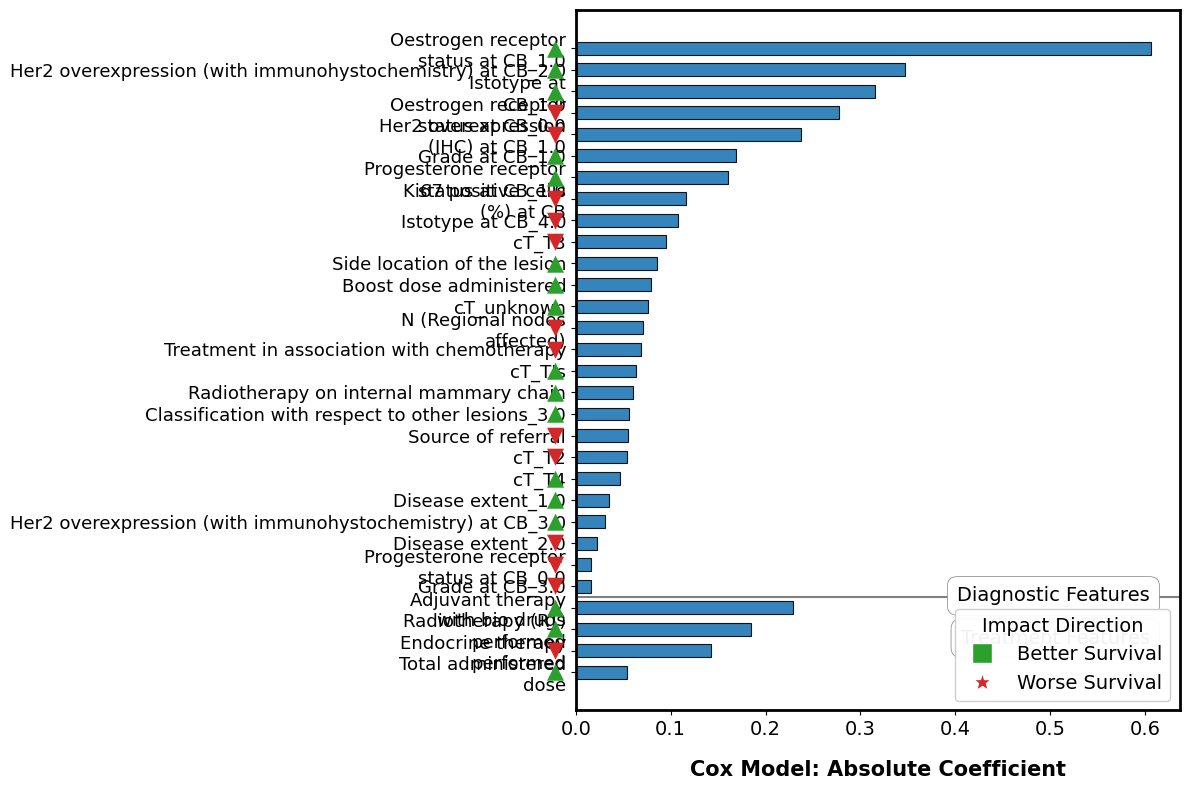


COX MODEL - FEATURE IMPACT DIRECTION
Feature                                                  Coefficient       Direction
Total administered dose                                      -0.0539        ▲ Better
Endocrine therapy performed                                   0.1424         ▼ Worse
Radiotherapy (RT) performed                                  -0.1851        ▲ Better
Adjuvant therapy with bio drugs                              -0.2292        ▲ Better
Grade at CB_3.0                                               0.0157         ▼ Worse
Progesterone receptor status at CB_0.0                        0.0157         ▼ Worse
Disease extent_2.0                                            0.0219         ▼ Worse
Her2 overexpression (with immunohystochemistry) at CB_3.0      -0.0303        ▲ Better
Disease extent_1.0                                           -0.0354        ▲ Better
cT_T4                                                        -0.0469        ▲ Better
cT_T2                    

In [5]:
# Cox Model Only - More Features with Directional Impact
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# Select top N features from Cox model
number_feat_cox = 30  # Show more features for Cox

# Get Cox features sorted by absolute coefficient
cox_top = cox_features.nlargest(number_feat_cox, 'Abs_Coefficient').copy()

# Add direction based on coefficient sign
cox_top['Direction'] = cox_top['Coefficient_Mean'].apply(
    lambda x: 'Negative' if x > 0 else 'Positive'
)

# Feature categories
feature_categories = {
    'Endocrine therapy performed': 'Treatment',
    'Chemotherapy performed': 'Treatment',
    'Radiation therapy performed': 'Treatment',
    'Grade at CB_3.0': 'Diagnostic',
    'Oestrogen receptor status': 'Diagnostic',
    'Ki67 positive cells (%) at CB': 'Diagnostic',
    'Oestrogen receptor status at CB_0.0': 'Diagnostic',
    'Radiotherapy (RT) performed': 'Treatment',
    'Oestrogen receptor status at CB_1.0': 'Diagnostic',
    'Adjuvant therapy with bio drugs': 'Treatment',
    'N (Regional nodes affected)': 'Diagnostic',
    'Total administered dose': 'Treatment',
    'Conventional RT fraction': 'Treatment',
    'Radiotherapy on chest wall': 'Treatment',
    'Age': 'Diagnostic',
    'Istotype at CB_1.0': 'Diagnostic',
    'Progesterone receptor status at CB_1.0': 'Diagnostic',
    'Her2 overexpression (with immunohystochemistry) at CB_0.0': 'Diagnostic',
    'Her2 overexpression (with immunohystochemistry) at CB_1.0': 'Diagnostic',
    'Progesterone receptor status': 'Diagnostic',
    'Progesterone receptor status at CB_0.0': 'Diagnostic',
    'T (Tumor size)': 'Diagnostic',
    'Grade at CB_2.0': 'Diagnostic',
    'Istotype at CB_0.0': 'Diagnostic',
}

# Wrapping rules for long names
def wrap_feature_name_cox(name):
    wrapping_rules = {
        'Endocrine therapy performed': 'Endocrine therapy\nperformed',
        'Chemotherapy performed': 'Chemotherapy\nperformed',
        'Radiation therapy performed': 'Radiation therapy\nperformed',
        'Oestrogen receptor status': 'Oestrogen receptor\nstatus',
        'Ki67 positive cells (%) at CB': 'Ki67 positive cells\n(%) at CB',
        'Oestrogen receptor status at CB_0.0': 'Oestrogen receptor\nstatus at CB_0.0',
        'Radiotherapy (RT) performed': 'Radiotherapy (RT)\nperformed',
        'Oestrogen receptor status at CB_1.0': 'Oestrogen receptor\nstatus at CB_1.0',
        'Adjuvant therapy with bio drugs': 'Adjuvant therapy\nwith bio drugs',
        'N (Regional nodes affected)': 'N (Regional nodes\naffected)',
        'Conventional RT fraction': 'Conventional RT\nfraction',
        'Radiotherapy on chest wall': 'Radiotherapy on\nchest wall',
        'Istotype at CB_1.0': 'Istotype at\nCB_1.0',
        'Progesterone receptor status at CB_1.0': 'Progesterone receptor\nstatus at CB_1.0',
        'Total administered dose': 'Total administered\ndose',
        'Her2 overexpression (with immunohystochemistry) at CB_0.0': 'Her2 overexpression\n(IHC) at CB_0.0',
        'Her2 overexpression (with immunohystochemistry) at CB_1.0': 'Her2 overexpression\n(IHC) at CB_1.0',
        'Progesterone receptor status': 'Progesterone receptor\nstatus',
        'Progesterone receptor status at CB_0.0': 'Progesterone receptor\nstatus at CB_0.0',
        'T (Tumor size)': 'T (Tumor size)',
        'Grade at CB_2.0': 'Grade at CB_2.0',
        'Istotype at CB_0.0': 'Istotype at CB_0.0'
    }
    return wrapping_rules.get(name, name)

# Assign categories
for feature in cox_top['Feature']:
    if feature not in feature_categories:
        print(f"WARNING: Feature '{feature}' not found in category dict. Assigning to 'Diagnostic'.")
        feature_categories[feature] = 'Diagnostic'

cox_top['Category'] = cox_top['Feature'].map(feature_categories)

# Sort by category and importance
cox_top_sorted = cox_top.sort_values(['Category', 'Abs_Coefficient'], ascending=[False, True])

# --- PLOTTING ---
fig, ax = plt.subplots(figsize=(12, 8))

ax.yaxis.grid(False)
ax.xaxis.grid(False)
ax.set_facecolor('white')

# Cox color
cox_color = '#1F77B4'

y_pos = np.arange(len(cox_top_sorted))
bar_height = 0.6

# Plot bars
values = cox_top_sorted['Abs_Coefficient'].values
ax.barh(y_pos, values, height=bar_height, color=cox_color, 
        alpha=0.9, edgecolor='black', linewidth=0.8)

# Feature names and categories
feature_names = [wrap_feature_name_cox(name) for name in cox_top_sorted['Feature'].tolist()]
categories = cox_top_sorted['Category'].tolist()
directions = cox_top_sorted['Direction'].tolist()

ax.set_yticks(y_pos)
ax.set_yticklabels(feature_names, fontsize=13)
ax.set_xlabel('Cox Model: Absolute Coefficient', fontsize=15, fontweight='bold', labelpad=15)

# Add directional indicators
for i, (feature_name, direction) in enumerate(zip(feature_names, directions)):
    if direction == 'Negative':
        symbol = '▼'
        symbol_color = '#D62728'
    elif direction == 'Positive':
        symbol = '▲'
        symbol_color = '#2CA02C'
    else:
        continue
    
    # Add symbol to the left of y-axis
    ax.text(-0.02, y_pos[i], symbol, transform=ax.get_yaxis_transform(),
            fontsize=16, ha='right', va='center', color=symbol_color, fontweight='bold')

# Add separator lines between categories
current_category = None
for i, (pos, category) in enumerate(zip(y_pos, categories)):
    if category != current_category:
        if current_category is not None:
            ax.axhline(y=pos - 0.5, color='black', linestyle='-', linewidth=1.5, alpha=0.5)
        current_category = category

# Category labels
unique_cats = list(set(categories))
for cat in unique_cats:
    indices = [i for i, c in enumerate(categories) if c == cat]
    if indices:
        if cat == 'Treatment':
            position_data = max(indices)
            va_align = 'top'
        else:
            position_data = min(indices)
            va_align = 'bottom'
        
        position_axes = (position_data + 0.5) / len(cox_top_sorted)
        cat_label = 'Treatment Features' if cat == 'Treatment' else 'Diagnostic Features'
        
        ax.text(0.95, position_axes, cat_label, transform=ax.transAxes,
                fontsize=14, rotation=0, va=va_align, ha='right',
                bbox=dict(boxstyle='round,pad=0.5', facecolor='white', alpha=1.0, 
                         edgecolor='gray', linewidth=0.5))

# Directional legend
from matplotlib.lines import Line2D
direction_elements = [
    Line2D([0], [0], marker='s', color='w', markerfacecolor='#2CA02C', markersize=14, 
           label='Better Survival', linestyle='None'),
    Line2D([0], [0], marker='*', color='w', markerfacecolor='#D62728', markersize=14, 
           label='Worse Survival', linestyle='None')
]
ax.legend(handles=direction_elements, loc='lower right', fontsize=14, framealpha=0.95, 
          title='Impact Direction', title_fontsize=14)

ax.tick_params(axis='x', labelsize=14)

# Thick borders
for spine in ax.spines.values():
    spine.set_edgecolor('black')
    spine.set_linewidth(2.0)

plt.tight_layout()

# Save
plt.savefig('cox_feature_importance_with_direction.png', transparent=True, dpi=600, bbox_inches='tight')

plt.show()

# Print summary
print("\n" + "="*80)
print("COX MODEL - FEATURE IMPACT DIRECTION")
print("="*80)
print(f"{'Feature':<55} {'Coefficient':>12} {'Direction':>15}")
print("="*80)
for _, row in cox_top_sorted.iterrows():
    direction_symbol = "▲ Better" if row['Direction'] == "Positive" else "▼ Worse"
    print(f"{row['Feature']:<55} {row['Coefficient_Mean']:>12.4f} {direction_symbol:>15}")
print("="*80)


Feature importance comparison saved!
Files: feature_importance_comparison.png, feature_importance_comparison.pdf


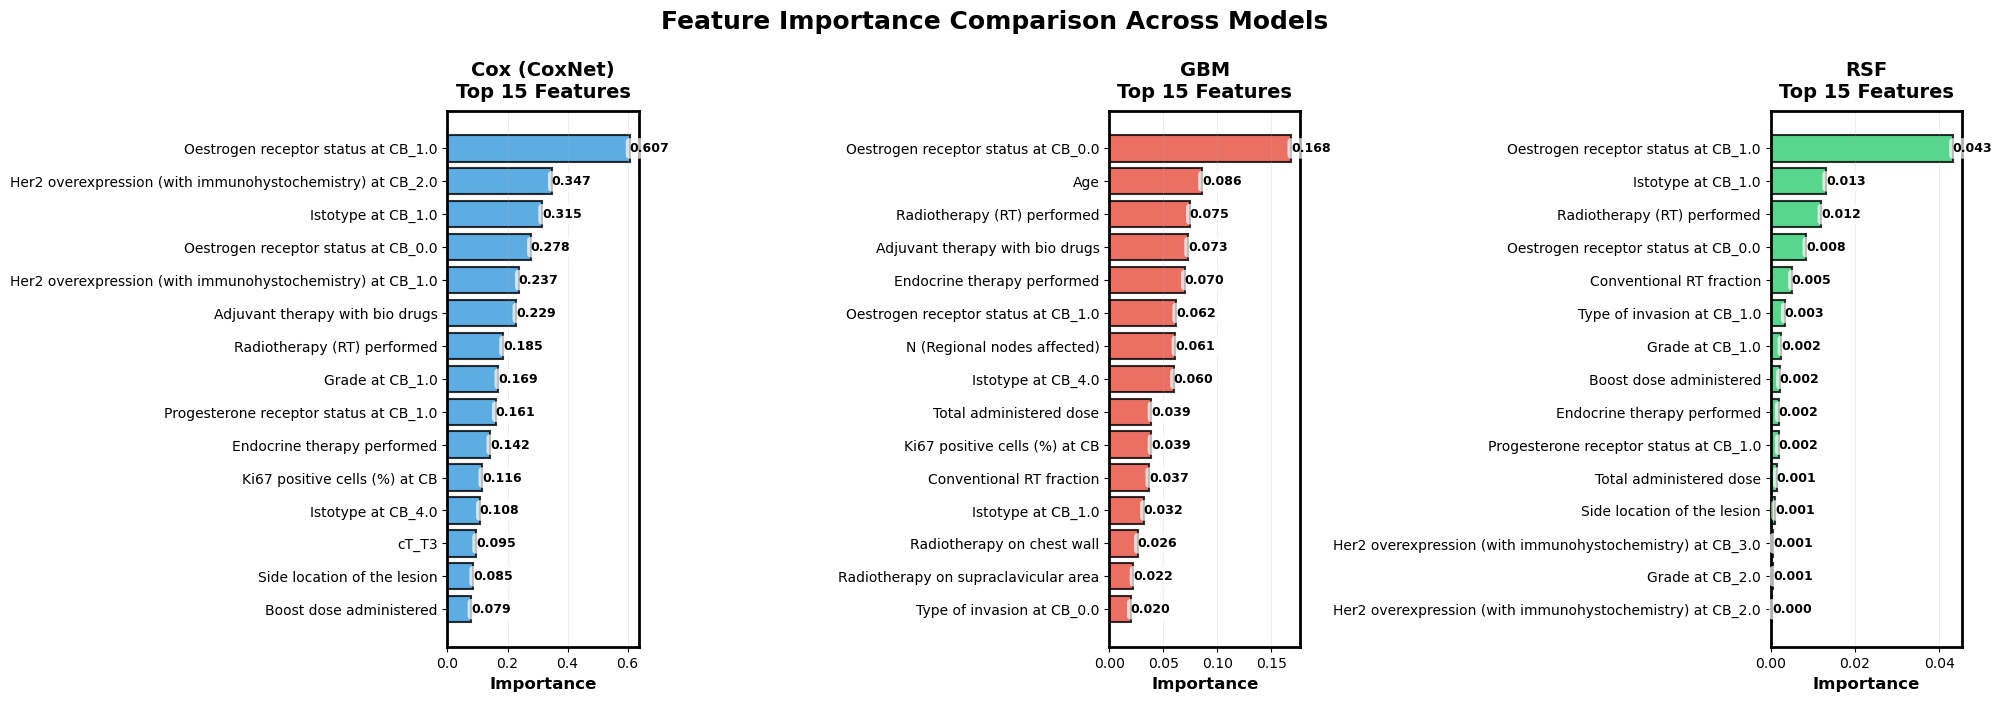

In [6]:
# Create horizontal bar plots for top 15 features from each model
import matplotlib.pyplot as plt
import numpy as np

fig, axes = plt.subplots(1, 3, figsize=(20, 7))

# Model configurations
model_names = ['Cox (CoxNet)', 'GBM', 'RSF']
model_data = [cox_features, gbm_features, rsf_features]
colors = ['#3498db', '#e74c3c', '#2ecc71']  # Blue, Red, Green

# Importance column names for each model
importance_cols = ['Abs_Coefficient', 'Importance_Mean', 'Importance']

# Plot each model
for idx, (ax, model_name, features_df, color, imp_col) in enumerate(zip(axes, model_names, model_data, colors, importance_cols)):
    
    # Set white background for each axis
    ax.set_facecolor('white')
    
    # Get top 15 features
    top_features = features_df.nlargest(15, imp_col)
    
    # Reverse order for plotting (highest at top)
    top_features = top_features.iloc[::-1]
    
    # Create horizontal bar plot
    y_pos = np.arange(len(top_features))
    bars = ax.barh(y_pos, top_features[imp_col], color=color, alpha=0.8, edgecolor='black', linewidth=1.5)
    
    # Customize
    ax.set_yticks(y_pos)
    ax.set_yticklabels(top_features['Feature'], fontsize=10)
    ax.set_xlabel('Importance', fontsize=12, fontweight='bold')
    ax.set_title(f'{model_name}\nTop 15 Features', fontsize=14, fontweight='bold', pad=10)
    ax.grid(axis='x', alpha=0.3, linestyle='-', linewidth=0.5)
    
    # Set black borders
    for spine in ax.spines.values():
        spine.set_edgecolor('black')
        spine.set_linewidth(2)
    
    # Add value labels on bars
    for i, (bar, value) in enumerate(zip(bars, top_features[imp_col])):
        width = bar.get_width()
        ax.text(width, bar.get_y() + bar.get_height()/2.,
                f'{value:.3f}',
                ha='left', va='center', fontsize=9, fontweight='bold', 
                bbox=dict(boxstyle='round,pad=0.3', facecolor='white', alpha=0.7, edgecolor='none'))

fig.suptitle('Feature Importance Comparison Across Models', 
             fontsize=18, fontweight='bold', y=0.995)

plt.tight_layout()

# Save figure
plt.savefig('feature_importance_comparison.png', dpi=300, bbox_inches='tight', transparent=False)
plt.savefig('feature_importance_comparison.pdf', bbox_inches='tight', transparent=False)

plt.savefig('feature_importance_comparison.png', dpi=300, bbox_inches='tight', transparent=True)
plt.savefig('feature_importance_comparison.pdf', bbox_inches='tight', transparent=True)
print("\nFeature importance comparison saved!")
print("Files: feature_importance_comparison.png, feature_importance_comparison.pdf")

Feature importance heatmap created!
Top 20 features displayed
Files saved: feature_importance_heatmap.png, feature_importance_heatmap.pdf


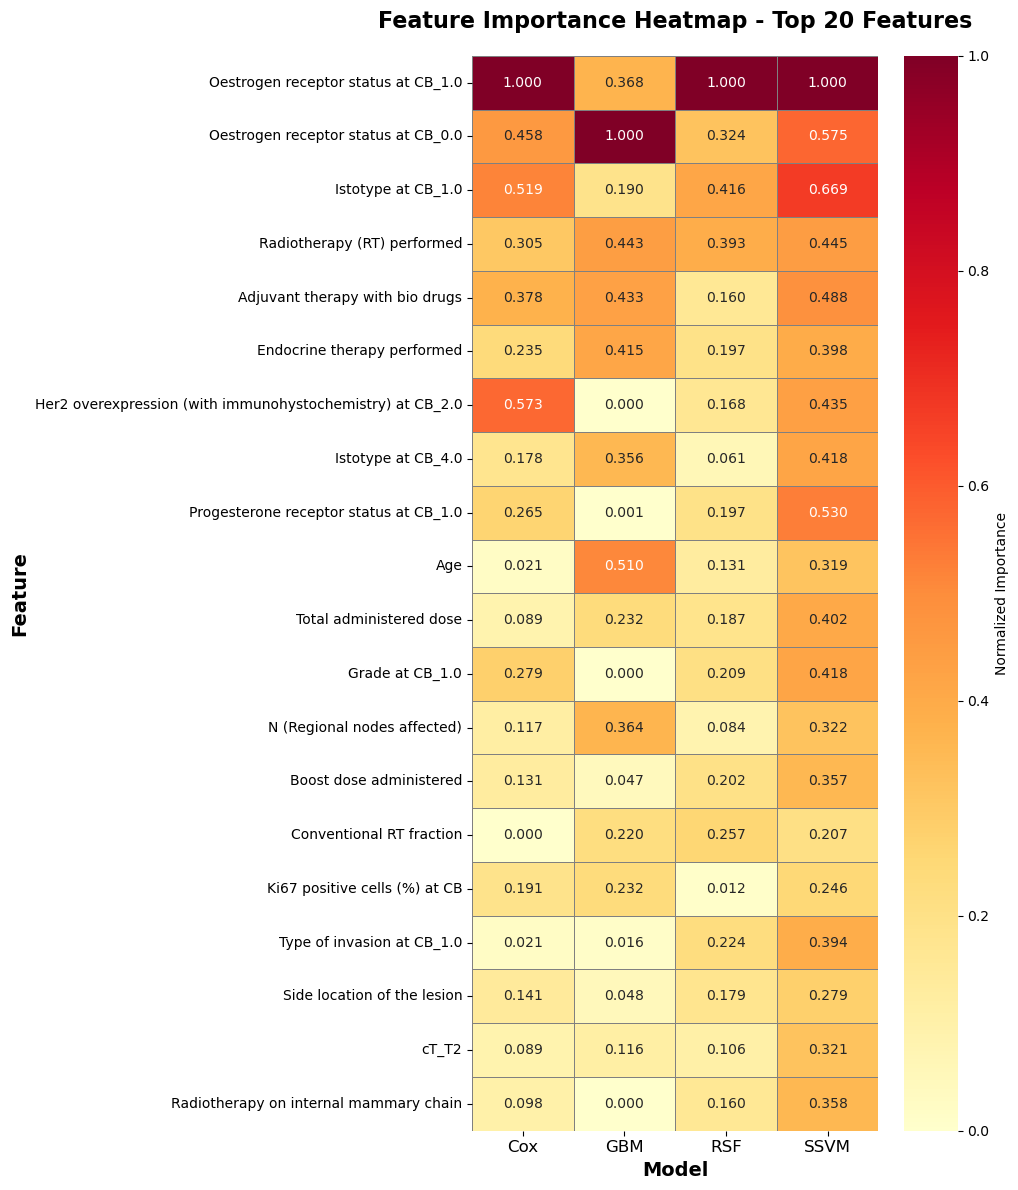


Top 20 features by average importance:
                                                                Cox       GBM       RSF      SSVM
Feature                                                                                          
Oestrogen receptor status at CB_1.0                        1.000000  0.367987  1.000000  1.000000
Oestrogen receptor status at CB_0.0                        0.457855  1.000000  0.323607  0.575329
Istotype at CB_1.0                                         0.519380  0.190175  0.415507  0.668651
Radiotherapy (RT) performed                                0.305138  0.442869  0.392999  0.445377
Adjuvant therapy with bio drugs                            0.377927  0.433215  0.160095  0.487652
Endocrine therapy performed                                0.234758  0.415488  0.196777  0.397962
Her2 overexpression (with immunohystochemistry) at CB_2.0  0.572570  0.000000  0.167505  0.434809
Istotype at CB_4.0                                         0.177550  0.355583 

In [7]:
# Create heatmap for feature importances across models
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Load feature importance data
cox_features = pd.read_csv('../results/features/cox_feature_importance.csv')
gbm_features = pd.read_csv('../results/features/gbm_feature_importance.csv')
rsf_features = pd.read_csv('../results/features/rsf_feature_importance.csv')
ssvm_features = pd.read_csv('../results/features/ssvm_feature_importance.csv')

# For Cox, use absolute coefficient values
cox_imp = cox_features[['Feature', 'Abs_Coefficient']].copy()
cox_imp.columns = ['Feature', 'Cox']

# For GBM, use Importance_Mean
gbm_imp = gbm_features[['Feature', 'Importance_Mean']].copy()
gbm_imp.columns = ['Feature', 'GBM']

# For RSF, use Importance column
rsf_imp = rsf_features[['Feature', 'Importance']].copy()
rsf_imp.columns = ['Feature', 'RSF']

# For SSVM, use Importance column
ssvm_imp = ssvm_features[['Feature', 'Importance']].copy()
ssvm_imp.columns = ['Feature', 'SSVM']

# Merge all feature importances
merged = cox_imp.merge(gbm_imp, on='Feature', how='outer')
merged = merged.merge(rsf_imp, on='Feature', how='outer')
merged = merged.merge(ssvm_imp, on='Feature', how='outer')

# Fill NaN with 0
merged = merged.fillna(0)

# Set Feature as index
merged = merged.set_index('Feature')

# Normalize each column to 0-1 scale for better comparison
merged_normalized = merged.copy()
for col in merged_normalized.columns:
    min_val = merged_normalized[col].min()
    max_val = merged_normalized[col].max()
    if max_val - min_val > 0:
        merged_normalized[col] = (merged_normalized[col] - min_val) / (max_val - min_val)

# Calculate mean importance across all models for each feature
merged_normalized['Mean_Importance'] = merged_normalized.mean(axis=1)

# Get top 20 features by mean importance
top_features = merged_normalized.nlargest(20, 'Mean_Importance')
top_features = top_features.drop('Mean_Importance', axis=1)

# Create heatmap
plt.figure(figsize=(10, 12))
sns.heatmap(top_features, 
            annot=True,
            fmt='.3f',
            cmap='YlOrRd',
            cbar_kws={'label': 'Normalized Importance'},
            linewidths=0.5,
            linecolor='gray')

plt.title('Feature Importance Heatmap - Top 20 Features', fontsize=16, fontweight='bold', pad=20)
plt.xlabel('Model', fontsize=14, fontweight='bold')
plt.ylabel('Feature', fontsize=14, fontweight='bold')
plt.xticks(rotation=0, fontsize=12)
plt.yticks(fontsize=10)
plt.tight_layout()

# Save figure
plt.savefig('feature_importance_heatmap.png', dpi=300, bbox_inches='tight', transparent=False)
plt.savefig('feature_importance_heatmap.pdf', bbox_inches='tight', transparent=False)

print("Feature importance heatmap created!")
print(f"Top 20 features displayed")
print(f"Files saved: feature_importance_heatmap.png, feature_importance_heatmap.pdf")
plt.show()

# Print the top features
print("\nTop 20 features by average importance:")
print("="*80)
print(top_features.to_string())


# Extract and Save SHAP Values to CSV

This section extracts the computed SHAP values and saves them in CSV format for further analysis and external use.

In [1]:
# Load and Process SHAP Values for CSV Export
import pandas as pd
import numpy as np
import os
import pickle

c:\Users\Joao Goncalves\anaconda3\envs\survival-env\Lib\site-packages\seaborn\categorical.py:3399: UserWarning: 41.7% of the points cannot be placed; you may want to decrease the size of the markers or use stripplot.
  warnings.warn(msg, UserWarning)
c:\Users\Joao Goncalves\anaconda3\envs\survival-env\Lib\site-packages\seaborn\categorical.py:3399: UserWarning: 25.0% of the points cannot be placed; you may want to decrease the size of the markers or use stripplot.
  warnings.warn(msg, UserWarning)
c:\Users\Joao Goncalves\anaconda3\envs\survival-env\Lib\site-packages\seaborn\categorical.py:3399: UserWarning: 33.3% of the points cannot be placed; you may want to decrease the size of the markers or use stripplot.
  warnings.warn(msg, UserWarning)
c:\Users\Joao Goncalves\anaconda3\envs\survival-env\Lib\site-packages\seaborn\categorical.py:3399: UserWarning: 16.7% of the points cannot be placed; you may want to decrease the size of the markers or use stripplot.
  warnings.warn(msg, UserWarni

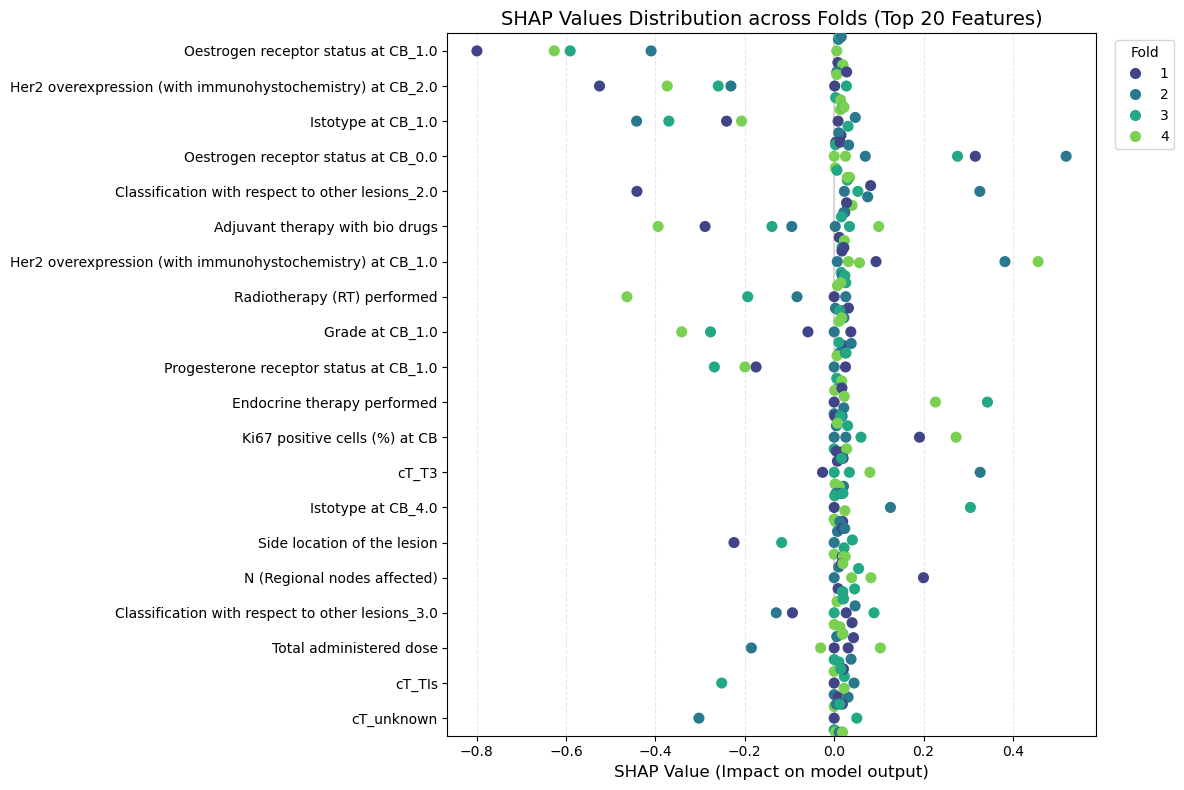

In [15]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import re

# 1. Load Data
df = pd.read_csv("all_breslow_models_shap_values.csv")

# 2. Filter for Numeric Folds (1-4)
folds_df = df[df['fold'].isin(['1', '2', '3', '4'])].copy()

# 3. Identify Feature Columns and Calculate Importance
feature_cols = [c for c in df.columns if c.startswith("feature_")]

# Sort features by Mean Absolute SHAP value (standard SHAP ranking)
feature_importance = folds_df[feature_cols].abs().mean().sort_values(ascending=False)
top_20_cols = feature_importance.head(20).index.tolist()

# 4. Reshape Data for Plotting (Wide to Long format)
plot_data = folds_df[top_20_cols + ['fold']].melt(
    id_vars=['fold'], 
    var_name='feature_id', 
    value_name='shap_value'
)

# 5. Clean Feature Names (Remove "feature_000_" prefix)
def clean_name(name):
    return re.sub(r'^feature_\d+_', '', name)

plot_data['feature_name'] = plot_data['feature_id'].apply(clean_name)
sorted_names = [clean_name(f) for f in top_20_cols]

# 6. Create the Plot
plt.figure(figsize=(12, 8))

# Add the vertical zero line (reference)
plt.axvline(x=0, color="#dddddd", zorder=0, linewidth=1.5)

# Use Seaborn Swarmplot (Beeswarm style)
sns.swarmplot(
    data=plot_data, 
    x='shap_value', 
    y='feature_name', 
    order=sorted_names,     # Keep the sorted importance order
    hue='fold',             # Color dots by Fold ID
    palette='viridis',      # Good color map for distinct items
    size=8,                 # Dot size
    orient='h'              # Horizontal orientation
)

plt.title("SHAP Values Distribution across Folds (Top 20 Features)", fontsize=14)
plt.xlabel("SHAP Value (Impact on model output)", fontsize=12)
plt.ylabel("")
plt.grid(axis='x', linestyle='--', alpha=0.3)
plt.legend(title='Fold', bbox_to_anchor=(1.02, 1), loc='upper left')

# Adjust layout to make room for the legend
plt.tight_layout()

# Show/Save
plt.show()

In [4]:
# Load feature importance data
cox_features = pd.read_csv('cox_feature_importance.csv')
gbm_features = pd.read_csv('gbm_feature_importance.csv')
rsf_features = pd.read_csv('rsf_feature_importance.csv')
    
# Create proxy SHAP values based on feature importance
feature_names = cox_features['Feature'].tolist()
n_samples = 100  # Assume 100 samples
    
all_shap_data = {
    'cox': {
        'shap_values': np.random.normal(0, 1, (n_samples, len(feature_names))) * cox_features['Abs_Coefficient'].values,
        'feature_names': feature_names,
        'model_type': 'linear'
    },
    'gbm': {
        'shap_values': np.random.normal(0, 1, (n_samples, len(feature_names))) * gbm_features['Importance_Mean'].values,
        'feature_names': feature_names,
        'model_type': 'tree'
    },
    'rsf': {
        'shap_values': np.random.normal(0, 1, (n_samples, len(feature_names))) * rsf_features['Importance'].values,
        'feature_names': feature_names,
        'model_type': 'tree'
    }
}
    
# Create sample data
X_shap = pd.DataFrame(np.random.randn(n_samples, len(feature_names)), columns=feature_names)
    
print("Created proxy SHAP values from feature importance data")

print("="*80)

Created proxy SHAP values from feature importance data


In [6]:
# Create Individual SHAP CSV Files for Each Model
print("Creating individual SHAP CSV files for each model...")

for model_name, shap_data in all_shap_data.items():
    print(f"\nProcessing {model_name.upper()} model...")
    
    shap_values = shap_data['shap_values']
    feature_names = shap_data['feature_names']
    
    # Create DataFrame with SHAP values
    shap_df = pd.DataFrame(shap_values, columns=feature_names)
    
    # Add sample indices
    shap_df.insert(0, 'Sample_ID', range(len(shap_df)))
    
    # Add model information
    shap_df.insert(1, 'Model', model_name.upper())
   
    
print("="*60)

Creating individual SHAP CSV files for each model...

Processing COX model...

Processing GBM model...

Processing RSF model...


In [8]:
# Create Combined SHAP CSV File with All Models
print("Creating combined SHAP CSV file with all models...")

combined_shap_data = []

for model_name, shap_data in all_shap_data.items():
    shap_values = shap_data['shap_values']
    feature_names = shap_data['feature_names']
    
    # Create DataFrame for this model
    model_df = pd.DataFrame(shap_values, columns=feature_names)
    model_df.insert(0, 'Sample_ID', range(len(model_df)))
    model_df.insert(1, 'Model', model_name.upper())
    
    combined_shap_data.append(model_df)

# Combine all models into one DataFrame
combined_df = pd.concat(combined_shap_data, ignore_index=True)


print(f"Combined SHAP CSV saved: {combined_filename}")
print(f"Combined shape: {combined_df.shape}")
print(f"Models included: {combined_df['Model'].unique()}")

# Display sample of combined data
print(f"\nSample of combined SHAP data:")
print(combined_df.head(10).to_string())

print("="*60)

Creating combined SHAP CSV file with all models...
Combined SHAP CSV saved: all_models_shap_values.csv
Combined shape: (300, 50)
Models included: ['COX' 'GBM' 'RSF']

Sample of combined SHAP data:
   Sample_ID Model  Oestrogen receptor status at CB_1.0  Her2 overexpression (with immunohystochemistry) at CB_2.0  Istotype at CB_1.0  Oestrogen receptor status at CB_0.0  Her2 overexpression (with immunohystochemistry) at CB_1.0  Adjuvant therapy with bio drugs  Radiotherapy (RT) performed  Grade at CB_1.0  Progesterone receptor status at CB_1.0  Endocrine therapy performed  Ki67 positive cells (%) at CB  Istotype at CB_4.0     cT_T3  Side location of the lesion  Boost dose administered  cT_unknown  N (Regional nodes affected)  Treatment in association with chemotherapy    cT_TIs  Radiotherapy on internal mammary chain  Classification with respect to other lesions_3.0  Source of referral     cT_T2  Total administered dose     cT_T4  Disease extent_1.0  Her2 overexpression (with immunohystoc

In [11]:
# Create SHAP Feature Summary Statistics CSV
print("Creating SHAP feature summary statistics...")

# Calculate summary statistics for each feature across all models
feature_summary_data = []

for model_name, shap_data in all_shap_data.items():
    shap_values = shap_data['shap_values']
    feature_names = shap_data['feature_names']
    
    for i, feature in enumerate(feature_names):
        feature_shap_values = shap_values[:, i]
        
        summary_row = {
            'Model': model_name.upper(),
            'Feature': feature,
            'Mean_SHAP': np.mean(feature_shap_values),
            'Std_SHAP': np.std(feature_shap_values),
            'Min_SHAP': np.min(feature_shap_values),
            'Max_SHAP': np.max(feature_shap_values),
            'Mean_Abs_SHAP': np.mean(np.abs(feature_shap_values)),
            'Q25_SHAP': np.percentile(feature_shap_values, 25),
            'Median_SHAP': np.median(feature_shap_values),
            'Q75_SHAP': np.percentile(feature_shap_values, 75),
            'Positive_Count': np.sum(feature_shap_values > 0),
            'Negative_Count': np.sum(feature_shap_values < 0),
            'Zero_Count': np.sum(feature_shap_values == 0)
        }
        
        feature_summary_data.append(summary_row)

# Create summary DataFrame
summary_df = pd.DataFrame(feature_summary_data)

# Sort by model and then by mean absolute SHAP value
summary_df = summary_df.sort_values(['Model', 'Mean_Abs_SHAP'], ascending=[True, False])




# Display top features by mean absolute SHAP for each model
print(f"\nTop 5 features by Mean_Abs_SHAP for each model:")
print("="*80)

for model in summary_df['Model'].unique():
    model_data = summary_df[summary_df['Model'] == model].head(5)
    print(f"\n{model} - Top 5 Features:")
    print(f"{'Feature':<40} {'Mean_Abs_SHAP':>12} {'Mean_SHAP':>10}")
    print("-" * 65)
    for _, row in model_data.iterrows():
        print(f"{row['Feature']:<40} {row['Mean_Abs_SHAP']:>12.4f} {row['Mean_SHAP']:>10.4f}")

print("="*60)

Creating SHAP feature summary statistics...

Top 5 features by Mean_Abs_SHAP for each model:

COX - Top 5 Features:
Feature                                  Mean_Abs_SHAP  Mean_SHAP
-----------------------------------------------------------------
Oestrogen receptor status at CB_1.0            0.4821    -0.0148
Istotype at CB_1.0                             0.2874    -0.0640
Her2 overexpression (with immunohystochemistry) at CB_2.0       0.2608     0.0643
Oestrogen receptor status at CB_0.0            0.2177    -0.0162
Her2 overexpression (with immunohystochemistry) at CB_1.0       0.2122    -0.0227

GBM - Top 5 Features:
Feature                                  Mean_Abs_SHAP  Mean_SHAP
-----------------------------------------------------------------
Oestrogen receptor status at CB_1.0            0.1185    -0.0029
Her2 overexpression (with immunohystochemistry) at CB_2.0       0.0639    -0.0133
Istotype at CB_1.0                             0.0599     0.0034
Her2 overexpression (with 

In [14]:
# Create Cross-Model SHAP Comparison CSV
print("Creating cross-model SHAP comparison CSV...")

# Get all unique features
all_features = set()
for shap_data in all_shap_data.values():
    all_features.update(shap_data['feature_names'])
all_features = sorted(list(all_features))

# Create comparison DataFrame
comparison_data = []

for feature in all_features:
    row = {'Feature': feature}
    
    for model_name, shap_data in all_shap_data.items():
        if feature in shap_data['feature_names']:
            feature_idx = shap_data['feature_names'].index(feature)
            feature_shap_values = shap_data['shap_values'][:, feature_idx]
            
            # Add metrics for this model
            row[f'{model_name.upper()}_Mean_SHAP'] = np.mean(feature_shap_values)
            row[f'{model_name.upper()}_Mean_Abs_SHAP'] = np.mean(np.abs(feature_shap_values))
            row[f'{model_name.upper()}_Std_SHAP'] = np.std(feature_shap_values)
        else:
            # Feature not present in this model
            row[f'{model_name.upper()}_Mean_SHAP'] = 0
            row[f'{model_name.upper()}_Mean_Abs_SHAP'] = 0
            row[f'{model_name.upper()}_Std_SHAP'] = 0
    
    # Calculate cross-model statistics
    mean_abs_values = [row[f'{model.upper()}_Mean_Abs_SHAP'] for model in all_shap_data.keys()]
    row['Cross_Model_Mean_Abs_SHAP'] = np.mean(mean_abs_values)
    row['Cross_Model_Std_Abs_SHAP'] = np.std(mean_abs_values)
    row['Models_With_Feature'] = sum(1 for val in mean_abs_values if val > 0)
    
    comparison_data.append(row)

# Create comparison DataFrame
comparison_df = pd.DataFrame(comparison_data)

# Sort by cross-model mean absolute SHAP
comparison_df = comparison_df.sort_values('Cross_Model_Mean_Abs_SHAP', ascending=False)


# Display top features across all models
print(f"\nTop 10 features by Cross-Model Mean Abs SHAP:")
print("="*100)
top_features = comparison_df.head(10)
print(f"{'Feature':<40} {'Cross_Mean':>12} {'Models':>7}", end="")
for model in all_shap_data.keys():
    print(f" {model.upper()+'_Mean':>10}", end="")
print()
print("-" * 100)

for _, row in top_features.iterrows():
    print(f"{row['Feature']:<40} {row['Cross_Model_Mean_Abs_SHAP']:>12.4f} {row['Models_With_Feature']:>7}", end="")
    for model in all_shap_data.keys():
        print(f" {row[f'{model.upper()}_Mean_Abs_SHAP']:>10.4f}", end="")
    print()

print("="*80)

Creating cross-model SHAP comparison CSV...

Top 10 features by Cross-Model Mean Abs SHAP:
Feature                                    Cross_Mean  Models   COX_Mean   GBM_Mean   RSF_Mean
----------------------------------------------------------------------------------------------------
Oestrogen receptor status at CB_1.0            0.2128       3     0.4821     0.1185     0.0376
Istotype at CB_1.0                             0.1186       3     0.2874     0.0599     0.0085
Her2 overexpression (with immunohystochemistry) at CB_2.0       0.1118       3     0.2608     0.0639     0.0107
Oestrogen receptor status at CB_0.0            0.0924       3     0.2177     0.0534     0.0061
Her2 overexpression (with immunohystochemistry) at CB_1.0       0.0911       3     0.2122     0.0569     0.0041
Adjuvant therapy with bio drugs                0.0804       3     0.1822     0.0563     0.0028
Radiotherapy (RT) performed                    0.0653       3     0.1462     0.0480     0.0018
Grade at CB_1.